# Exploring the mouse cerebellum RNA-seq datasets
27 selected runs from **PRJNA875066** (aging time course, GSE212336) and **PRJNA946653** (rejuvenation: acute dietary restriction / young plasma, GSE227689); both from Hahn et al., *Cell* 2023.
Raw FASTQs are **not** needed here: GEO provides gene-count tables for all 15 regions, which we subset to cerebellum (`cer`).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from pathlib import Path
ROOT = Path('..') if Path('metadata').exists()==False else Path('.')
ROOT = Path.cwd()
meta = pd.read_csv(ROOT/'metadata/sra_metadata.csv')
meta['mouse_id'] = meta.mouse_id.astype(int)
meta['group'] = meta.condition.where(meta.BioProject=='PRJNA946653', 'aging ' + meta.age_months.astype(str) + 'mo')
print(meta.shape); meta[['SRR','BioProject','age_months','sex','tissue','condition','mouse_id','sra_size_MB']].head()

(27, 18)


,SRR,BioProject,age_months,sex,tissue,condition,mouse_id,sra_size_MB
0,SRR21355392,PRJNA875066,3,female,Cerebellum,untreated aging cohort,37,1792
1,SRR21355388,PRJNA875066,3,female,Cerebellum,untreated aging cohort,41,1850
2,SRR21355401,PRJNA875066,3,male,Cerebellum,untreated aging cohort,29,1596
3,SRR21355396,PRJNA875066,3,male,Cerebellum,untreated aging cohort,33,2887
4,SRR21355390,PRJNA875066,18,female,Cerebellum,untreated aging cohort,39,3080


## 1. Sample overview
Number of samples by project, age, sex, tissue and treatment.

In [2]:
for cols in (['BioProject','tissue'],['BioProject','age_months'],['BioProject','sex'],['BioProject','condition']):
    print(meta.groupby(cols).size().to_frame('n'),'\n')
print(meta.groupby(['BioProject','condition','age_months','sex']).size().unstack('sex',fill_value=0))
missing = meta.isna().sum(); print('\nColumns with missing values:', missing[missing>0].to_dict() or 'none')

                         n
BioProject  tissue        
PRJNA875066 Cerebellum  12
PRJNA946653 Cerebellum  15 

                         n
BioProject  age_months    
PRJNA875066 3            4
            18           4
            21           4
PRJNA946653 19          15 

                    n
BioProject  sex      
PRJNA875066 female  6
            male    6
PRJNA946653 female  9
            male    6 

                                     n
BioProject  condition                 
PRJNA875066 untreated aging cohort  12
PRJNA946653 AL                       4
            PBS                      3
            YMP                      3
            aDR                      5 

sex                                            female  male
BioProject  condition              age_months              
PRJNA875066 untreated aging cohort 3                2     2
                                   18               2     2
                                   21               2     2
PRJNA946653 AL   

### Possible comparisons
| Project | Comparison | n per group | Notes |
|---|---|---|---|
| PRJNA875066 | 3 vs 18 vs 21 months | 4 each (2M+2F) | sex can be a covariate; only 2 per sex per age |
| PRJNA946653 | aDR vs AL | 5 vs 4 | females only |
| PRJNA946653 | YMP vs PBS | 3 vs 3 | males only; very low power |
| across projects | 19-mo AL/PBS vs 18/21-mo aging | - | **confounded** with cohort/batch: use only as a sanity check |

Sample sizes are small, so expect low power; effects reported in the paper for cerebellum are mostly aging-driven.

## 2. Load processed count matrices (GEO)

In [3]:
def load(p): 
    d = pd.read_csv(p, sep='\t', index_col=0); return d
aging_all = load(ROOT/'processed_data/GSE212336/GSE212336_BulkSeq_Counttable.txt.gz')
rej_all   = load(ROOT/'processed_data/GSE227689/GSE227689_BulkSeqRejuvenation_Counttable.txt.gz')
for n,d in (('aging (all regions)',aging_all),('rejuvenation (all regions)',rej_all)):
    print(n, d.shape, '| NaN:', int(d.isna().sum().sum()), '| dup genes:', int(d.index.duplicated().sum()), '| non-integer:', bool((d.values%1!=0).any()))
print('regions in aging table:', sorted({c.split('_')[1] for c in aging_all.columns}))

aging (all regions) (21076, 847) | NaN: 0 | dup genes: 0 | non-integer: False
rejuvenation (all regions) (21076, 238) | NaN: 0 | dup genes: 0 | non-integer: False
regions in aging table: ['cc', 'cer', 'cor', 'cp', 'ent', 'hi', 'hi2', 'hy', 'med', 'olf', 'plx', 'pon', 'svz', 'th', 'vis']


Columns are named `BulkSeq_<region>_<mouseID>`. We keep cerebellum (`cer`) and match `mouse_id` to the SRA/BioSample metadata. Matching is checked explicitly.

In [4]:
def cer(d):
    c = [x for x in d.columns if x.split('_')[1]=='cer']
    out = d[c].copy(); out.columns = [int(x.split('_')[-1]) for x in c]; return out
cer_aging, cer_rej = cer(aging_all), cer(rej_all)
ma = meta[meta.BioProject=='PRJNA875066']; mr = meta[meta.BioProject=='PRJNA946653']
print('aging  : metadata ids not in matrix:', set(ma.mouse_id)-set(cer_aging.columns), '| matrix ids without metadata:', sorted(set(cer_aging.columns)-set(ma.mouse_id)))
print('rejuv. : metadata ids not in matrix:', set(mr.mouse_id)-set(cer_rej.columns),   '| matrix ids without metadata:', sorted(set(cer_rej.columns)-set(mr.mouse_id)))

aging  : metadata ids not in matrix: set() | matrix ids without metadata: [1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 30, 34, 38, 42, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]
rejuv. : metadata ids not in matrix: set() | matrix ids without metadata: []


In [5]:
counts = pd.concat([cer_aging[ma.mouse_id], cer_rej[mr.mouse_id]], axis=1)
assert counts.index.equals(aging_all.index) and (aging_all.index==rej_all.index).all()
meta = pd.concat([ma,mr]).reset_index(drop=True)
counts.columns = meta.SRR.values
print('cerebellum matrix (genes x samples):', counts.shape)
keep = (counts>=10).sum(axis=1) >= 3
print('genes with >=10 counts in >=3 samples:', int(keep.sum()))

cerebellum matrix (genes x samples): (21076, 27)
genes with >=10 counts in >=3 samples: 14115


## 3. Library sizes and expression distribution
Bar chart = total counts per sample (library size). Boxplots = distribution of log2(CPM+1) over expressed genes, which should be similar across samples after CPM normalisation.

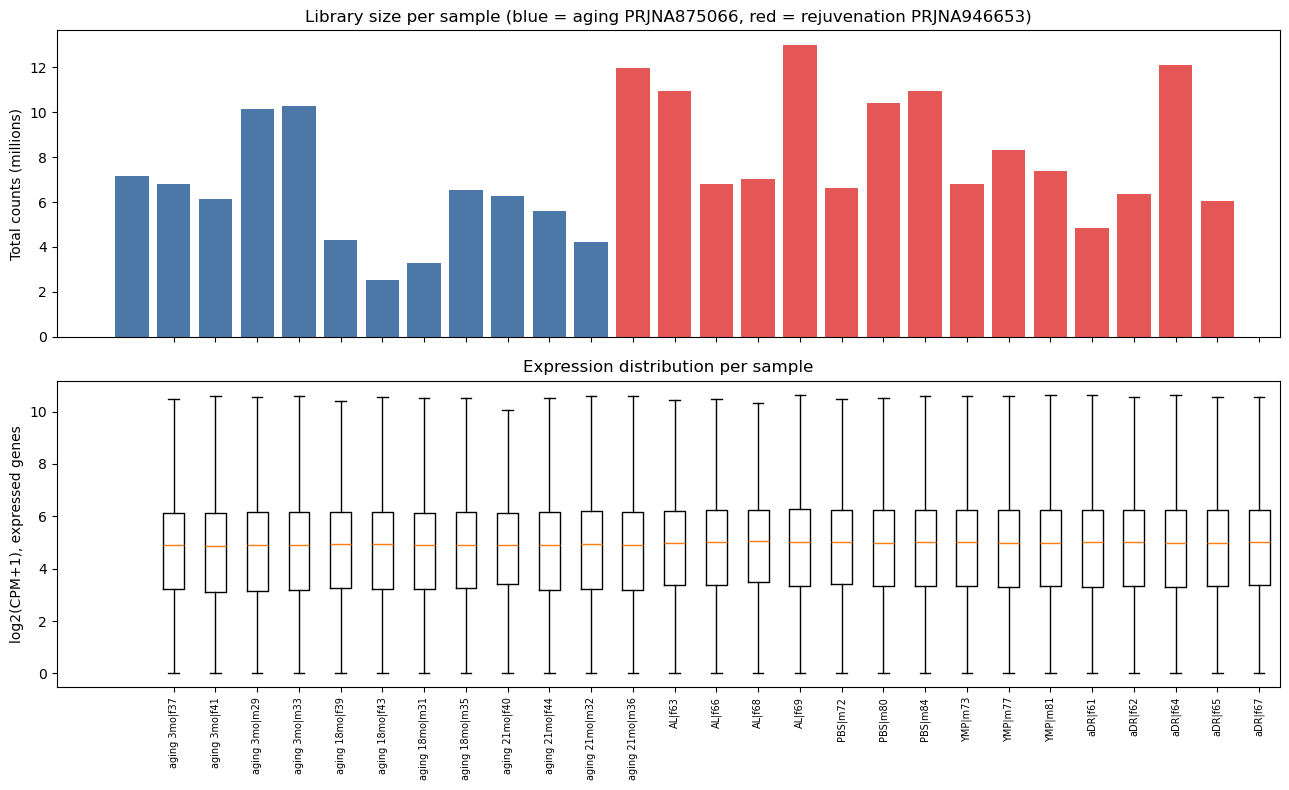

In [6]:
lib = counts.sum(); cpm = counts.div(lib)*1e6; lcpm = np.log2(cpm+1)
cols = {'PRJNA875066':'#4c78a8','PRJNA946653':'#e45756'}
fig,ax = plt.subplots(2,1,figsize=(13,8),sharex=True)
ax[0].bar(range(len(lib)), lib.values/1e6, color=meta.BioProject.map(cols))
ax[0].set_ylabel('Total counts (millions)'); ax[0].set_title('Library size per sample (blue = aging PRJNA875066, red = rejuvenation PRJNA946653)')
ax[1].boxplot([lcpm.loc[keep,s] for s in lcpm.columns], showfliers=False)
ax[1].set_ylabel('log2(CPM+1), expressed genes'); ax[1].set_title('Expression distribution per sample')
ax[1].set_xticks(range(1,len(lib)+1)); ax[1].set_xticklabels(meta.group+'|'+meta.sex.str[0]+meta.mouse_id.astype(str), rotation=90, fontsize=7)
plt.tight_layout(); plt.savefig(ROOT/'results/library_size_and_distribution.png',dpi=150); plt.show()

## 4. PCA
PCA on log2 CPM of the 2,000 most variable expressed genes (centered). Each point is one sample; axes show % variance explained.

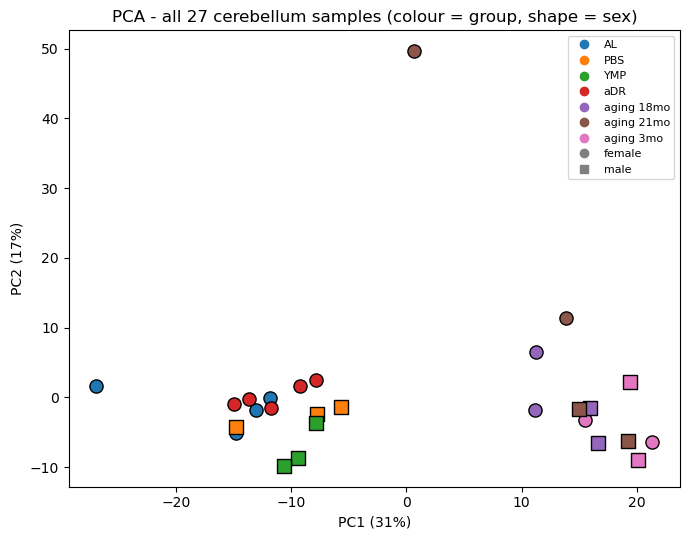

In [7]:
def pca_plot(sub, color, marker, title, fn):
    X = lcpm.loc[keep, sub.SRR]; top = X.var(axis=1).nlargest(2000).index
    Xc = X.loc[top].T; Xc = Xc-Xc.mean()
    p = PCA(n_components=4).fit(Xc); sc = p.transform(Xc)
    fig,ax = plt.subplots(figsize=(7,5.5))
    for lab,m in zip(sorted(sub[color].unique()), 'osD^v<>'):
        pass
    cmap = dict(zip(sorted(sub[color].unique()), plt.cm.tab10.colors))
    mk = dict(zip(sorted(sub[marker].unique()), 'os^D'))
    for i,(s,r) in enumerate(sub.iterrows()):
        ax.scatter(sc[i,0],sc[i,1],c=[cmap[r[color]]],marker=mk[r[marker]],s=90,edgecolor='k')
    from matplotlib.lines import Line2D
    h=[Line2D([],[],marker='o',ls='',color=c,label=k) for k,c in cmap.items()]+[Line2D([],[],marker=m,ls='',color='grey',label=k) for k,m in mk.items()]
    ax.legend(handles=h,fontsize=8,loc='best'); ax.set_xlabel(f'PC1 ({p.explained_variance_ratio_[0]:.0%})'); ax.set_ylabel(f'PC2 ({p.explained_variance_ratio_[1]:.0%})'); ax.set_title(title)
    plt.tight_layout(); plt.savefig(ROOT/f'results/{fn}',dpi=150); plt.show()
pca_plot(meta, 'group', 'sex', 'PCA - all 27 cerebellum samples (colour = group, shape = sex)', 'pca_all27.png')

**Reading the plot:** if the two projects separate on PC1/PC2 regardless of biology, that is a cohort/batch effect (different mice, ages at collection, facilities, library prep dates). Cross-project comparisons should therefore be avoided; analyse each project separately.

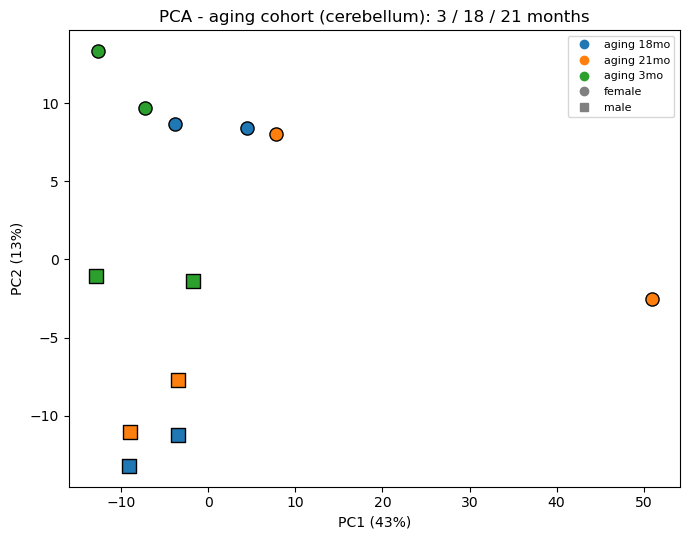

In [8]:
pca_plot(meta[meta.BioProject=='PRJNA875066'].reset_index(drop=True), 'group', 'sex', 'PCA - aging cohort (cerebellum): 3 / 18 / 21 months', 'pca_aging.png')

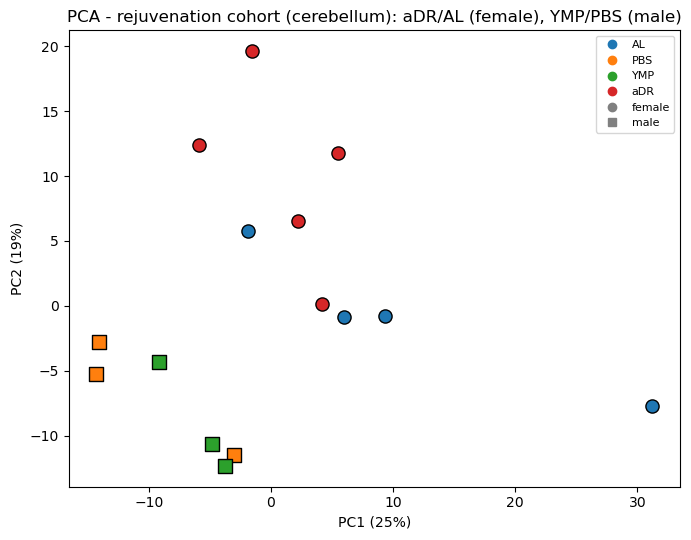

In [9]:
rj = meta[meta.BioProject=='PRJNA946653'].reset_index(drop=True)
pca_plot(rj, 'condition', 'sex', 'PCA - rejuvenation cohort (cerebellum): aDR/AL (female), YMP/PBS (male)', 'pca_rejuvenation.png')

## 5. Sanity check with known aging genes
The paper highlights complement/immune genes (e.g. *C4b*, *Trem2*, *Gfap*) rising with age, with the cerebellum among the fastest-aging regions.

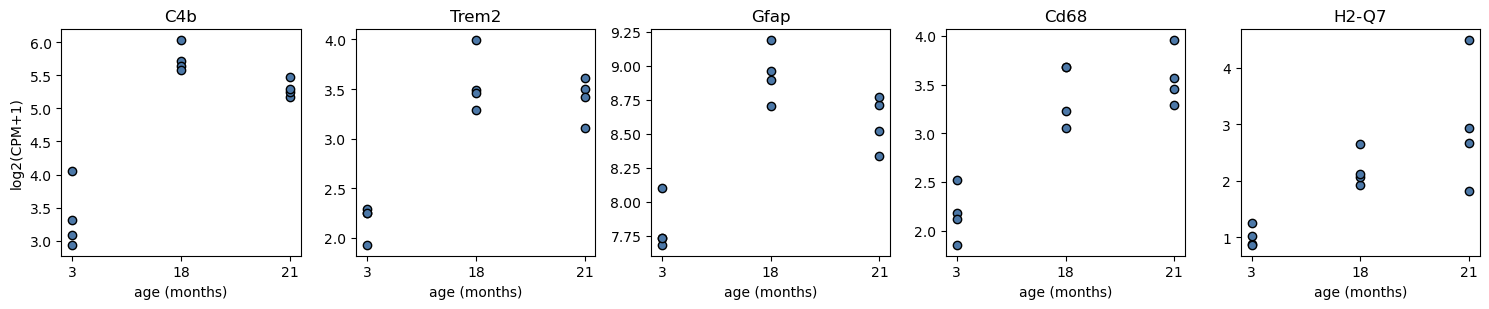

In [10]:
genes = [g for g in ['C4b','Trem2','Gfap','Cd68','H2-Q7'] if g in lcpm.index]
a = meta[meta.BioProject=='PRJNA875066']
fig,axs = plt.subplots(1,len(genes),figsize=(3*len(genes),3.2),sharex=True)
for ax,g in zip(np.atleast_1d(axs),genes):
    for age,x in zip((3,18,21),(0,1,2)):
        v = lcpm.loc[g, a[a.age_months==age].SRR]; ax.scatter([x]*len(v),v,c='#4c78a8',edgecolor='k')
    ax.set_title(g); ax.set_xticks([0,1,2]); ax.set_xticklabels(['3','18','21']); ax.set_xlabel('age (months)')
np.atleast_1d(axs)[0].set_ylabel('log2(CPM+1)'); plt.tight_layout(); plt.savefig(ROOT/'results/aging_marker_genes.png',dpi=150); plt.show()

## 6. Save tidy outputs

In [11]:
counts.to_csv(ROOT/'processed_data/cerebellum_counts_27runs.csv.gz'); meta.to_csv(ROOT/'metadata/sra_metadata_with_group.csv',index=False)
print('saved')

saved
